In [1]:
# import cython
import numpy as np
import matplotlib.pyplot as plt 
import glob

In [2]:
from OXmodeCython import OXmode_cython

In [3]:
# Check that MPS is available
import torch
from unet import UNet, TransformerNet
import torchvision.transforms as transforms

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)

# if not torch.backends.mps.is_available():
#     if not torch.backends.mps.is_built():
#         print("MPS not available because the current PyTorch install was not "
#               "built with MPS enabled.")
#     else:
#         print("MPS not available because the current MacOS version is not 12.3+ "
#               "and/or you do not have an MPS-enabled device on this machine.")

# else:
#     device = torch.device("mps")

cuda:0


In [5]:
savedmodel_list = glob.glob1('saved_model','TOPHAT_checkpoint_epoch_1*')
savedmodel_list.sort()
for f in savedmodel_list:
    loss = torch.load('saved_model/'+f)['loss'].item()
    print(f, ':', loss)

/tmp/ipykernel_132767/3772612073.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  loss = torch.load('saved_model/'+f)['loss'].item()


TOPHAT_checkpoint_epoch_10_12505_loss0.7463.pth : 0.7463171482086182
TOPHAT_checkpoint_epoch_10_25005_loss0.7527.pth : 0.7527132034301758
TOPHAT_checkpoint_epoch_10_5_loss0.7490.pth : 0.7490103840827942
TOPHAT_checkpoint_epoch_11_12505_loss0.7560.pth : 0.756045401096344
TOPHAT_checkpoint_epoch_11_25005_loss0.7596.pth : 0.7596163153648376
TOPHAT_checkpoint_epoch_11_5_loss0.7474.pth : 0.7474130988121033
TOPHAT_checkpoint_epoch_12_12505_loss0.7507.pth : 0.7507175803184509
TOPHAT_checkpoint_epoch_12_25005_loss0.7529.pth : 0.7528881430625916
TOPHAT_checkpoint_epoch_12_5_loss0.7580.pth : 0.7579764127731323
TOPHAT_checkpoint_epoch_13_12505_loss0.7515.pth : 0.7514982223510742
TOPHAT_checkpoint_epoch_13_25005_loss0.7551.pth : 0.7550525069236755
TOPHAT_checkpoint_epoch_13_5_loss0.7604.pth : 0.7603530883789062
TOPHAT_checkpoint_epoch_14_12505_loss0.7544.pth : 0.7543638348579407
TOPHAT_checkpoint_epoch_14_25005_loss0.7554.pth : 0.7554243803024292
TOPHAT_checkpoint_epoch_14_5_loss0.7525.pth : 0.752

In [10]:
# model = UNet(n_channels=3, n_classes=4, up_kernel_size=3)
target_size = [512,408]

model = TransformerNet(n_channels=1, n_classes=4,input_size=target_size, in_dropout_p = 0.25, dropout_p=0.3)
# model.load_state_dict(torch.load('saved_model/TOPHAT_checkpoint_epoch_13_35000.pth')['model_state_dict']) #,map_location=torch.device('cpu')
model.load_state_dict(torch.load('saved_model/TOPHAT_checkpoint_epoch_15_25005_loss0.7591.pth')['model_state_dict'])
model = model.to(device=device)
model.eval()

/tmp/ipykernel_132767/1092005117.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('saved_model/TOPHAT_checkpoint_epoch_15_25005_loss0.759

TransformerNet(
  (att): Transformer(
    (in_linear): Linear(in_features=512, out_features=1024, bias=True)
    (out_linear): Linear(in_features=1024, out_features=2048, bias=True)
    (blocks): Sequential(
      (0): Transformer_element(
        (c_attn): Linear(in_features=1024, out_features=3072, bias=False)
        (mlp): Sequential(
          (0): Linear(in_features=1024, out_features=1024, bias=False)
          (1): ReLU(inplace=True)
        )
        (mhatt): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=1024, out_features=1024, bias=True)
        )
        (relu): ReLU(inplace=True)
        (ln): GroupNorm(1, 408, eps=1e-05, affine=True)
      )
      (1): Transformer_element(
        (c_attn): Linear(in_features=1024, out_features=3072, bias=False)
        (mlp): Sequential(
          (0): Linear(in_features=1024, out_features=1024, bias=False)
          (1): ReLU(inplace=True)
        )
        (mhatt): MultiheadAttention(
          (

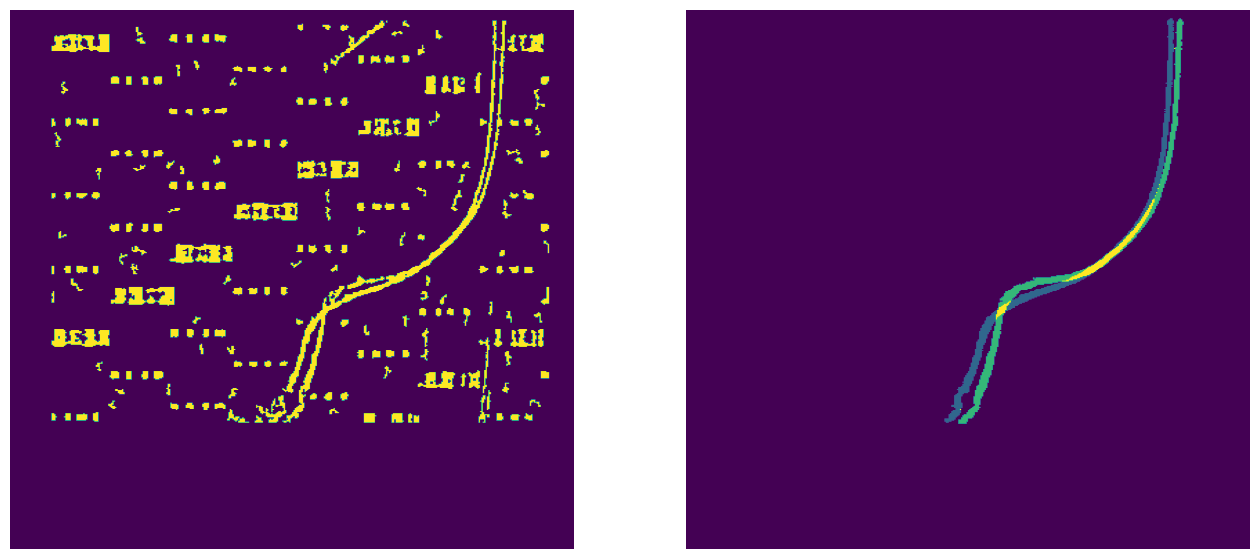

In [20]:
import glob
testfiles = glob.glob1('VIPIR_PROC/proc/','*.npy')
# resize_tr = transforms.Resize((572, 572), antialias = False)

# testim = np.load('VIPIR_PROC/proc/' + testfiles[0], allow_pickle=True, fix_imports=True)[()]
# testim = torch.from_numpy(testim['mask_full']).float()
# XX, YY = torch.meshgrid(torch.linspace(0,1,572,dtype=torch.float32),torch.linspace(0,1,572,dtype=torch.float32))
 
with torch.no_grad():
    
    file = testfiles[np.random.randint(0,len(testfiles)-1)]
    testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]

    testimage1 = torch.from_numpy(testdata['mask_full']).float()
    testimage1 = testimage1[None,None,:,:]# resize_tr(testimage1[None,None,:,:])
    img = testimage1 #torch.cat([testimage1,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)
    img = img.to('cuda')
    label1 = model(img)
    label1 = label1.squeeze().to('cpu')
    # transform = transforms.ToPILImage()
    # img = transform(label1)
    imgO = torch.argmax(label1[0:2,:,:],dim=0).detach().cpu()
    imgX = torch.argmax(label1[2:4,:,:],dim=0).detach().cpu()
    
    fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(16, 7))
    # plt.title(f'epoch{epoch_num}_{file}')
    ax = axs[0]
    ax.imshow(testimage1.detach().squeeze(), origin='lower', aspect = 'auto')
    ax.axis('off')
    ax = axs[1]

    ax.imshow(imgO.numpy() + imgX.numpy()*2, origin='lower', aspect = 'auto')
    ax.axis('off')

# resize_back = transforms.Resize(ionogram.shape)


In [8]:
testfiles = glob.glob1('VIPIR_PROC/proc/','*.npy')
# resize_tr = transforms.Resize((572, 572), antialias = False)
# resize_back = transforms.Resize(ionogram.shape)
# testim = np.load('VIPIR_PROC/proc/' + testfiles[0], allow_pickle=True, fix_imports=True)[()]
# testim = torch.from_numpy(testim['mask_full']).float()
# XX, YY = torch.meshgrid(torch.linspace(0,1,572,dtype=torch.float32),torch.linspace(0,1,572,dtype=torch.float32))
 
with torch.no_grad():
    for file in testfiles:
        # file = testfiles[np.random.randint(0,len(testfiles)-1)]
        testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]

        testimage1 = torch.from_numpy(testdata['mask_full']).float()
        # testimage1 = resize_tr(testimage1[None,None,:,:])
        # img = torch.cat([testimage1,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)
        img = testimage1[None,None,:,:]
        img = img.to('cuda')
        label1 = model(img)
        label1 = label1.squeeze().detach().cpu()

        imgO = torch.argmax(label1[0:2,:,:],dim=0)
        imgX = torch.argmax(label1[2:4,:,:],dim=0)
        imgO = imgO[None,:,:].squeeze().numpy() # resize_back(imgO[None,:,:]).squeeze().numpy()
        imgX = imgX[None,:,:].squeeze().numpy() # resize_back(imgX[None,:,:]).squeeze().numpy()
        testimage1 = testimage1.detach().squeeze().numpy()
        
        fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(16, 7))
        plt.title(f'{file}')
        ax = axs[0]
        ax.imshow(testimage1, origin='lower', aspect = 'auto')
        ax.axis('off')
        ax = axs[1]

        ax.imshow(imgO + imgX*2, origin='lower', aspect = 'auto')
        ax.axis('off')

        plt.savefig(f'seg_result_transformer/{file[:-4]}.png', bbox_inches='tight')
        plt.close()

        np.save(f'seg_result_transformer/{file}', {'filename':file, 'image':testimage1, 'imgO': imgO, 'imgX': imgX})